DATASET LOADED SUCCESSFULLY

First 5 Rows:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0



Last 5 Rows:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0
99999,Female,57.0,0,0,current,22.43,6.6,90,0



Dataset Shape:
(100000, 9)

Total Rows    : 100000
Total Columns : 9

Column Names:
['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']

Data Types:
gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  ob

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,100000,3,Female,58552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,100000.0,NaN,NaN,NaN,41.885856,22.51684,0.08,24.0,43.0,60.0,80.0
hypertension,100000.0,NaN,NaN,NaN,0.07485,0.26315,0.0,0.0,0.0,0.0,1.0
heart_disease,100000.0,NaN,NaN,NaN,0.03942,0.194593,0.0,0.0,0.0,0.0,1.0
smoking_history,100000,6,No Info,35816,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,100000.0,NaN,NaN,NaN,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,NaN,NaN,NaN,5.527507,1.070672,3.5,4.8,5.8,6.2,9.0
blood_glucose_level,100000.0,NaN,NaN,NaN,138.05806,40.708136,80.0,100.0,140.0,159.0,300.0
diabetes,100000.0,NaN,NaN,NaN,0.085,0.278883,0.0,0.0,0.0,0.0,1.0


... (3 outputs left out)

gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64


Smoking History Distribution:


smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64


Diabetes Target Distribution:
diabetes
0    91500
1     8500
Name: count, dtype: int64

Diabetes Target Percentage:
diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64


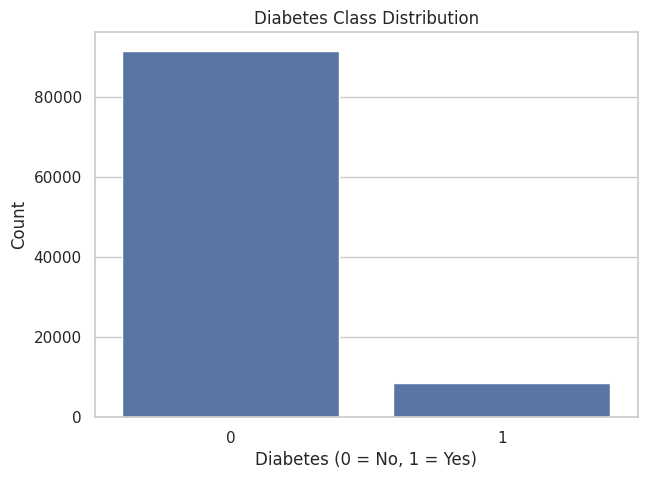

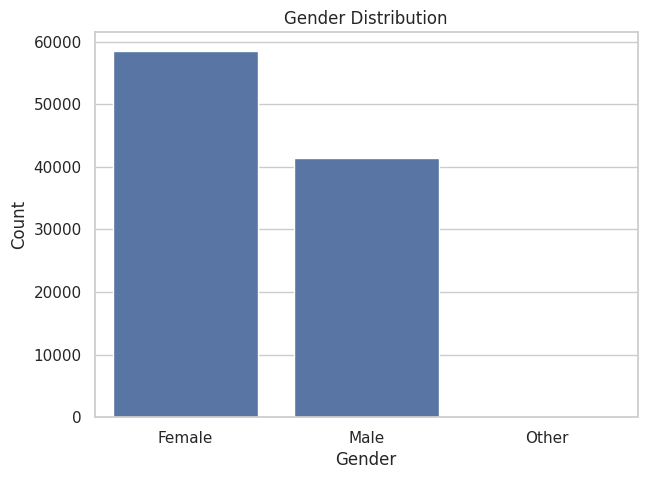

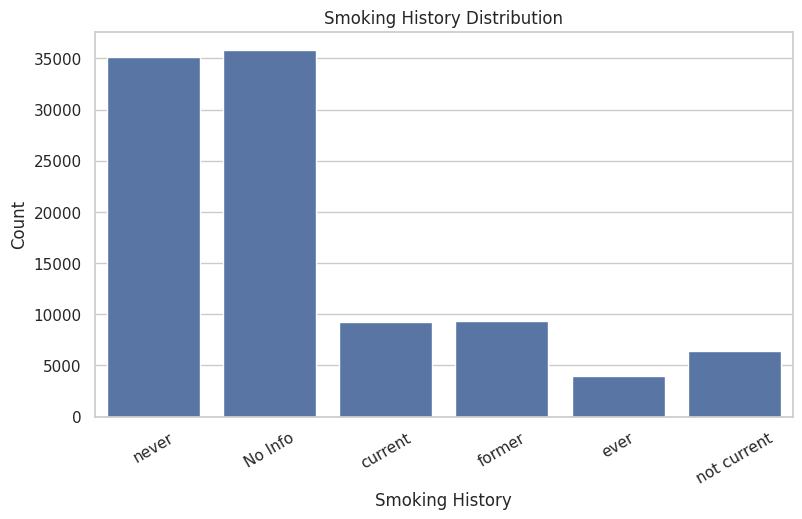

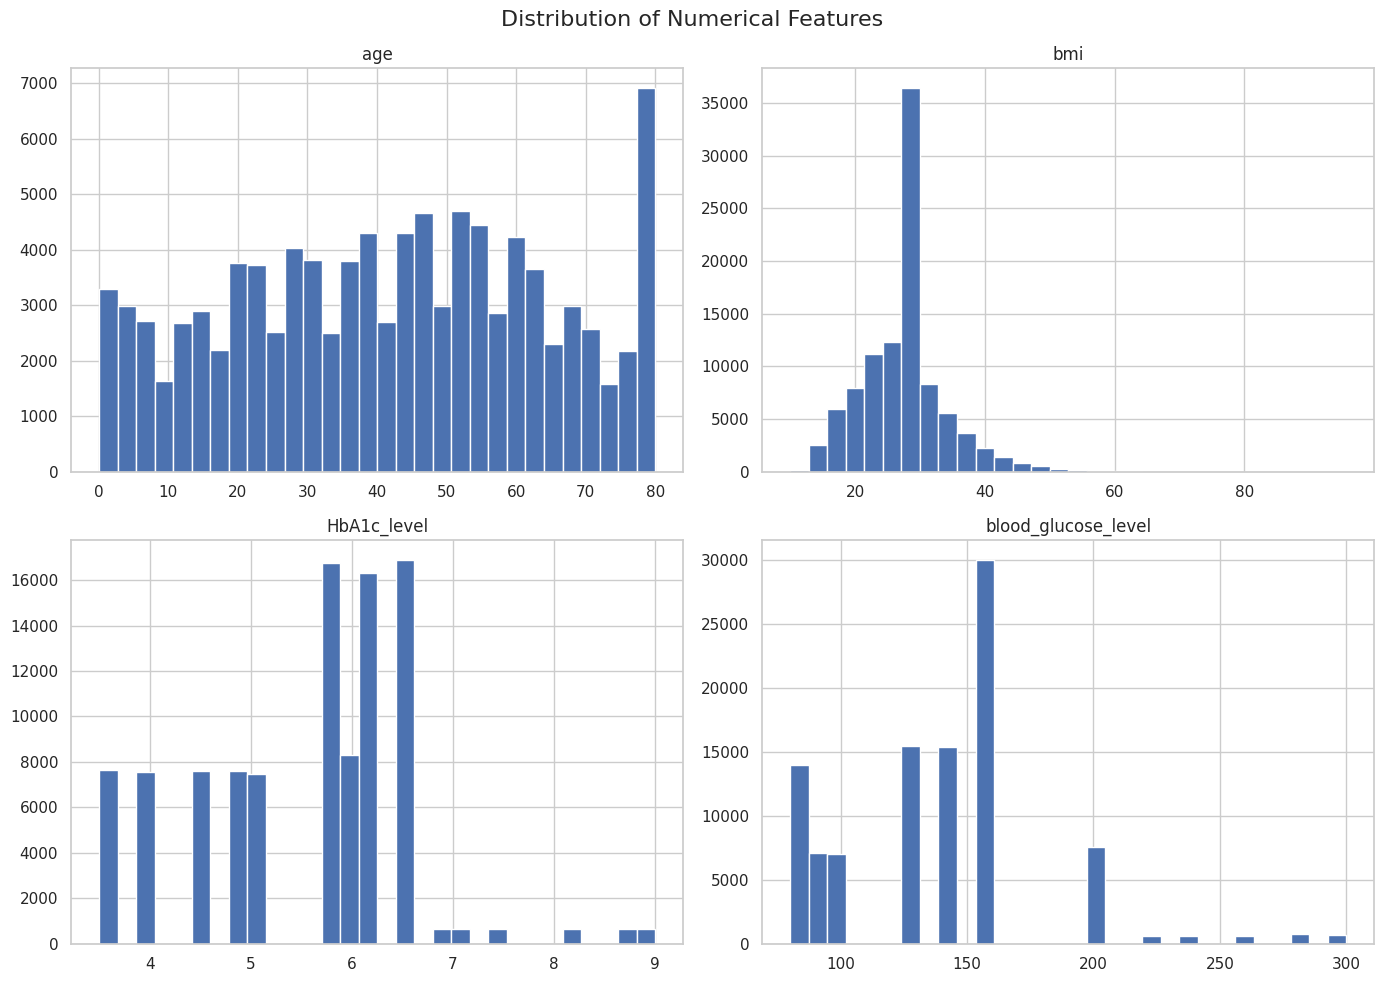

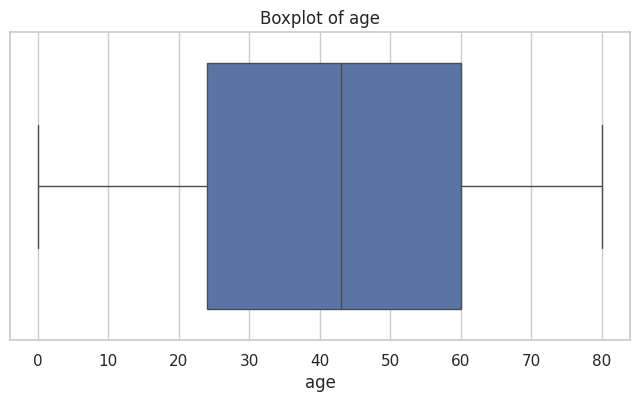

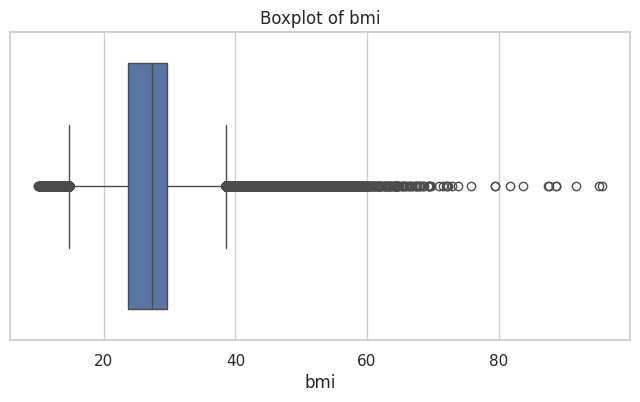

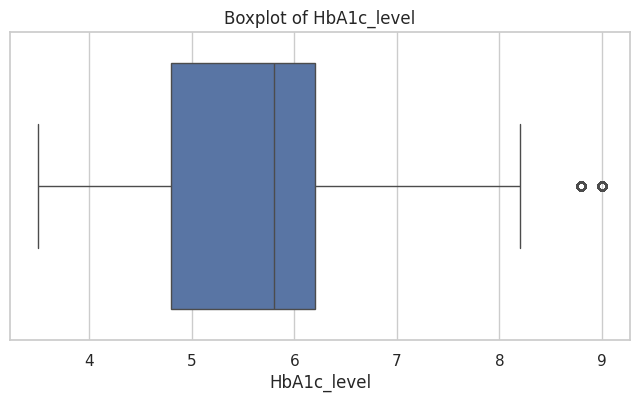

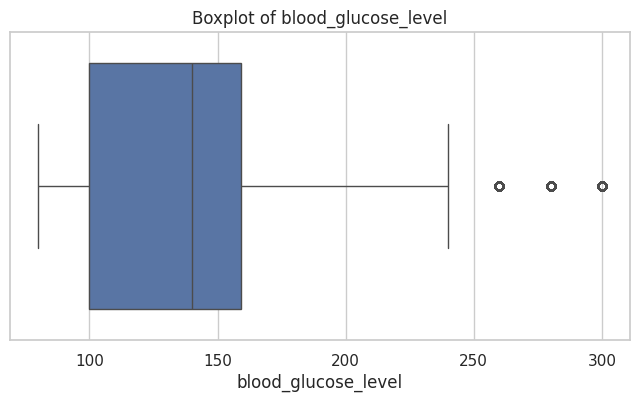

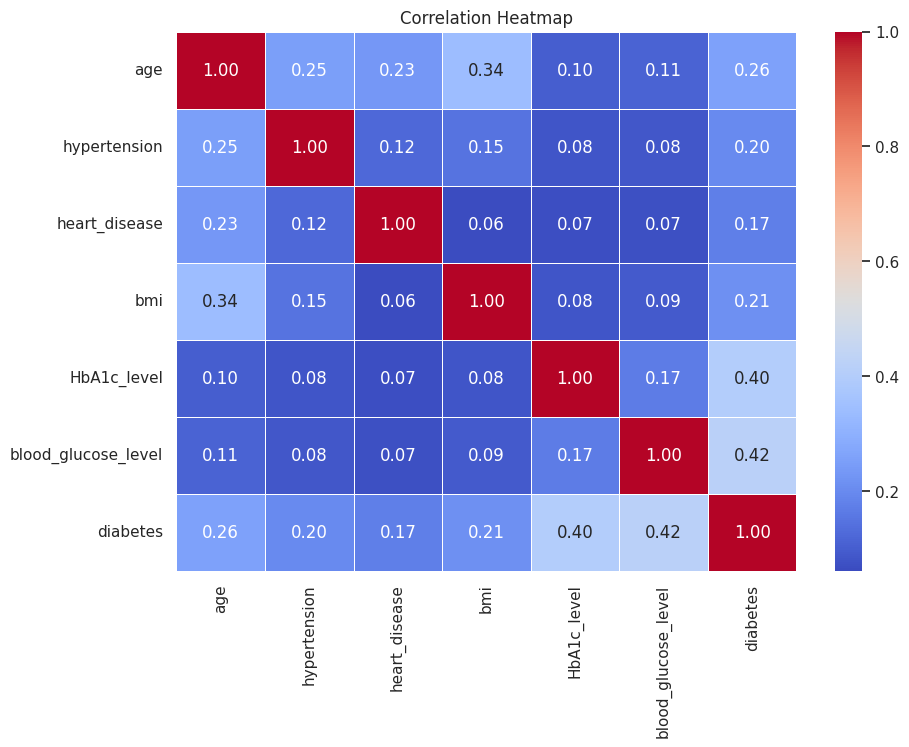

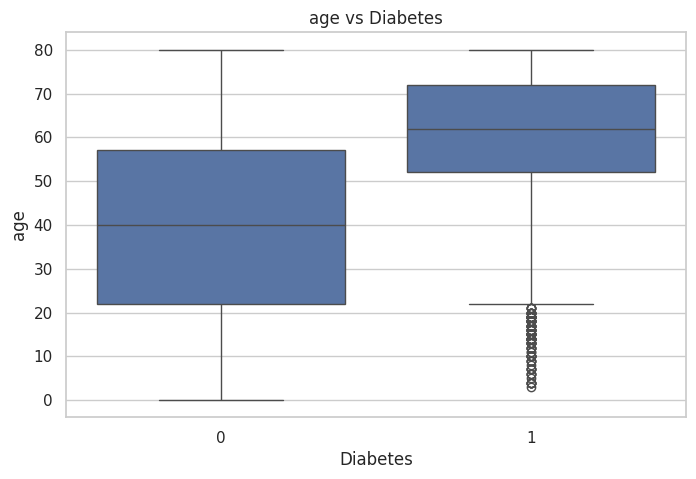

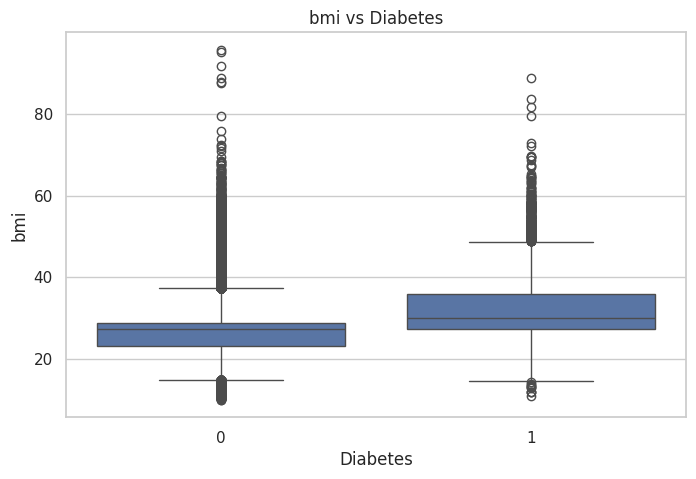

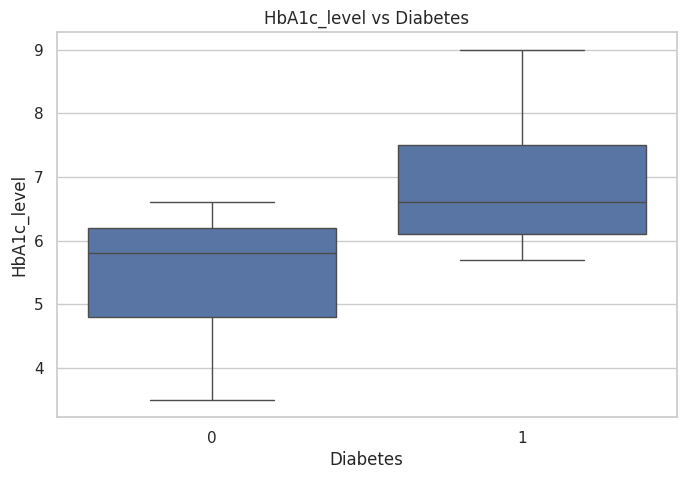

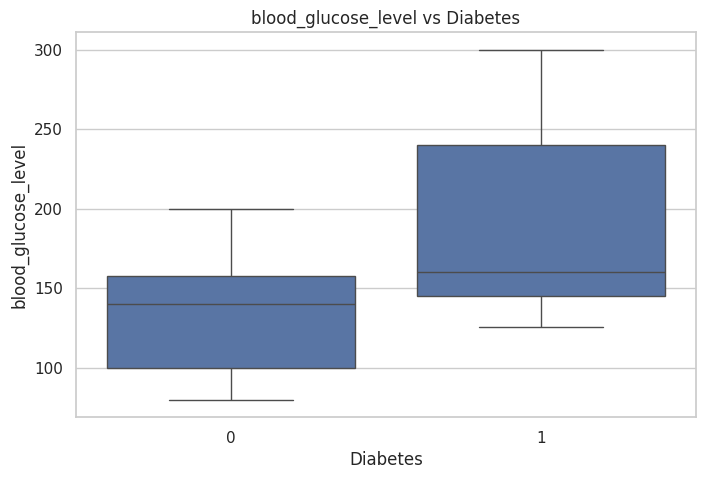

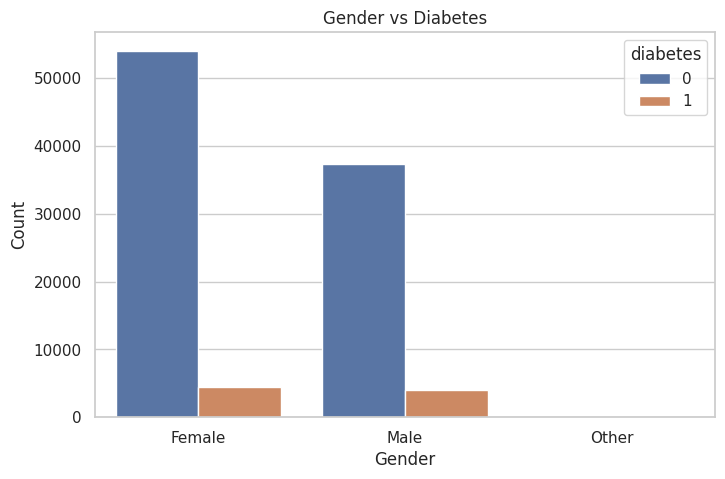

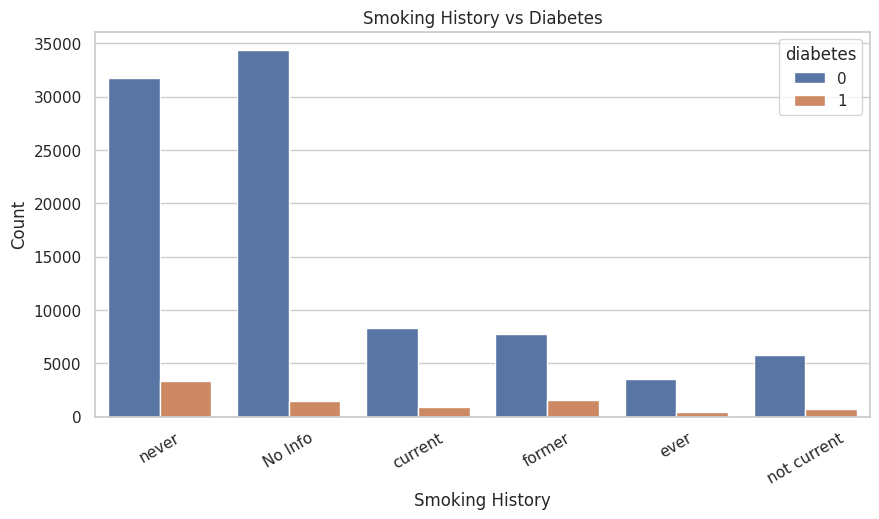

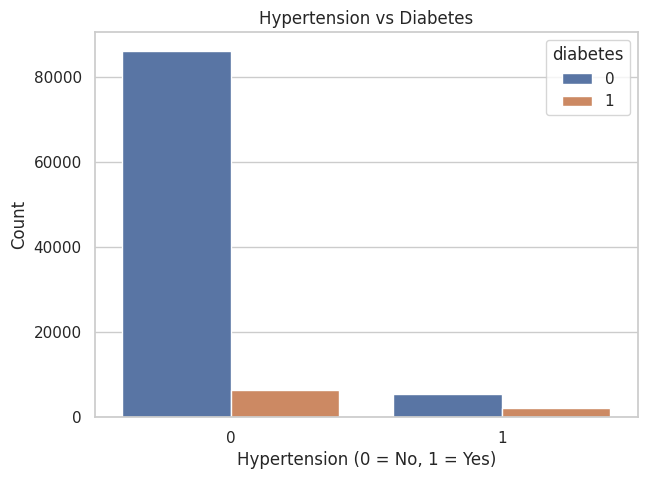

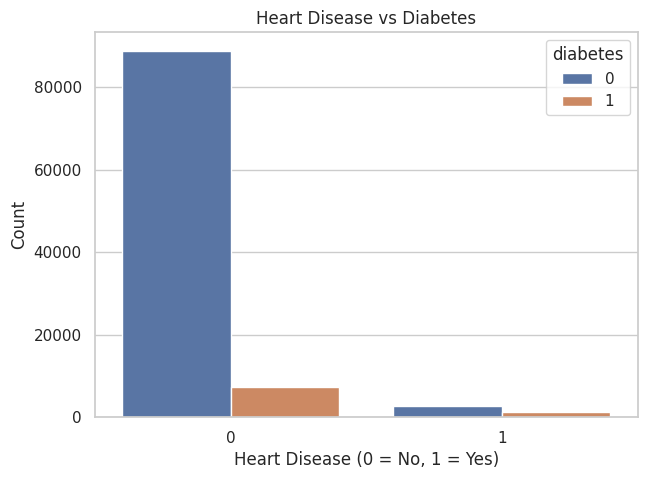


Diabetes Percentage by Gender:


diabetes,0,1
gender,,
Female,92.38,7.62
Male,90.25,9.75
Other,100.00,0.00



Diabetes Percentage by Smoking History:


diabetes,0,1
smoking_history,,
No Info,95.94,4.06
current,89.79,10.21
ever,88.21,11.79
former,83.00,17.00
never,90.47,9.53
not current,89.30,10.70



EDA COMPLETED SUCCESSFULLY


In [1]:
# ============================================================
# Diabetes Prediction Dataset - Load Dataset + Complete EDA
# ============================================================

# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Load Dataset
path = "/kaggle/input/datasets/sartajhuccain/thfthdytyj/diabetes_prediction_dataset.csv"

df = pd.read_csv(path)

# 3. Basic Information
print("=" * 60)
print("DATASET LOADED SUCCESSFULLY")
print("=" * 60)

print("\nFirst 5 Rows:")
display(df.head())

print("\nLast 5 Rows:")
display(df.tail())

# 4. Dataset Shape
print("\nDataset Shape:")
print(df.shape)

print(f"\nTotal Rows    : {df.shape[0]}")
print(f"Total Columns : {df.shape[1]}")

# 5. Column Names
print("\nColumn Names:")
print(df.columns.tolist())

# 6. Data Types
print("\nData Types:")
print(df.dtypes)

# 7. Dataset Information
print("\nDataset Information:")
df.info()

# 8. Statistical Summary
print("\nStatistical Summary:")
display(df.describe(include="all").T)

# 9. Missing Values
print("\nMissing Values:")
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Values": missing,
    "Percentage": missing_percent
})

display(missing_table)

# 10. Duplicate Values
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# 11. Unique Values
print("\nUnique Values:")
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

# 12. Value Counts for Categorical Columns
print("\nGender Distribution:")
display(df["gender"].value_counts())

print("\nSmoking History Distribution:")
display(df["smoking_history"].value_counts())

# 13. Target Variable Distribution
print("\nDiabetes Target Distribution:")
print(df["diabetes"].value_counts())

print("\nDiabetes Target Percentage:")
print((df["diabetes"].value_counts(normalize=True) * 100).round(2))

# ============================================================
# VISUALIZATION
# ============================================================

sns.set_theme(style="whitegrid")

# 14. Target Distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="diabetes")
plt.title("Diabetes Class Distribution")
plt.xlabel("Diabetes (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

# 15. Gender Distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="gender")
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

# 16. Smoking History Distribution
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="smoking_history")
plt.title("Smoking History Distribution")
plt.xlabel("Smoking History")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.show()

# 17. Numerical Columns
numeric_cols = [
    "age",
    "bmi",
    "HbA1c_level",
    "blood_glucose_level"
]

# Histograms
df[numeric_cols].hist(
    figsize=(14, 10),
    bins=30
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

# 18. Boxplots for Numerical Features
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.show()

# 19. Correlation Heatmap
plt.figure(figsize=(10, 7))

# Only numerical columns for correlation
corr = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

# 20. Numerical Features vs Diabetes
for col in numeric_cols:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x="diabetes", y=col)
    plt.title(f"{col} vs Diabetes")
    plt.xlabel("Diabetes")
    plt.ylabel(col)
    plt.show()

# 21. Gender vs Diabetes
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="gender", hue="diabetes")
plt.title("Gender vs Diabetes")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

# 22. Smoking History vs Diabetes
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="smoking_history", hue="diabetes")
plt.title("Smoking History vs Diabetes")
plt.xlabel("Smoking History")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.show()

# 23. Hypertension vs Diabetes
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="hypertension", hue="diabetes")
plt.title("Hypertension vs Diabetes")
plt.xlabel("Hypertension (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

# 24. Heart Disease vs Diabetes
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="heart_disease", hue="diabetes")
plt.title("Heart Disease vs Diabetes")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

# 25. Diabetes Rate by Gender
gender_diabetes = pd.crosstab(
    df["gender"],
    df["diabetes"],
    normalize="index"
) * 100

print("\nDiabetes Percentage by Gender:")
display(gender_diabetes.round(2))

# 26. Diabetes Rate by Smoking History
smoking_diabetes = pd.crosstab(
    df["smoking_history"],
    df["diabetes"],
    normalize="index"
) * 100

print("\nDiabetes Percentage by Smoking History:")
display(smoking_diabetes.round(2))

print("\n" + "=" * 60)
print("EDA COMPLETED SUCCESSFULLY")
print("=" * 60)

In [2]:
# ============================================================
# Diabetes Prediction Dataset - PREPROCESSING
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# ============================================================
# 1. Load Dataset
# ============================================================

path = "/kaggle/input/datasets/sartajhuccain/thfthdytyj/diabetes_prediction_dataset.csv"

df = pd.read_csv(path)

print("Original Dataset Shape:", df.shape)

# ============================================================
# 2. Remove Duplicate Rows
# ============================================================

print("\nDuplicate rows before:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("Duplicate rows after:", df.duplicated().sum())
print("Dataset Shape after removing duplicates:", df.shape)

# ============================================================
# 3. Separate Features and Target
# ============================================================

X = df.drop("diabetes", axis=1)
y = df["diabetes"]

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())

# ============================================================
# 4. Identify Numerical and Categorical Columns
# ============================================================

categorical_cols = [
    "gender",
    "smoking_history"
]

numerical_cols = [
    "age",
    "hypertension",
    "heart_disease",
    "bmi",
    "HbA1c_level",
    "blood_glucose_level"
]

print("\nCategorical Columns:")
print(categorical_cols)

print("\nNumerical Columns:")
print(numerical_cols)

# ============================================================
# 5. Train-Test Split
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape :", X_test.shape)

# ============================================================
# 6. Numerical Preprocessing
# ============================================================

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# ============================================================
# 7. Categorical Preprocessing
# ============================================================

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

# ============================================================
# 8. Combine Preprocessing
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

# ============================================================
# 9. Fit Transform on Training Data
# ============================================================

X_train_processed = preprocessor.fit_transform(X_train)

# Transform Test Data
X_test_processed = preprocessor.transform(X_test)

# ============================================================
# 10. Get Feature Names
# ============================================================

feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

# ============================================================
# 11. Display Processed Data
# ============================================================

print("\nProcessed Training Data:")
display(X_train_processed.head())

print("\nProcessed Testing Data:")
display(X_test_processed.head())

# ============================================================
# 12. Final Shapes
# ============================================================

print("\nFinal Preprocessed Shapes:")
print("X_train:", X_train_processed.shape)
print("X_test :", X_test_processed.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

# ============================================================
# 13. Check Missing Values
# ============================================================

print("\nMissing Values in X_train:")
print(X_train_processed.isnull().sum().sum())

print("\nMissing Values in X_test:")
print(X_test_processed.isnull().sum().sum())

# ============================================================
# 14. Target Distribution After Split
# ============================================================

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

print("\nTraining Target Percentage:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting Target Percentage:")
print((y_test.value_counts(normalize=True) * 100).round(2))

print("\n" + "=" * 60)
print("PREPROCESSING COMPLETED SUCCESSFULLY")
print("=" * 60)

Original Dataset Shape: (100000, 9)

Duplicate rows before: 3854
Duplicate rows after: 0
Dataset Shape after removing duplicates: (96146, 9)

Features:
['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level']

Target Distribution:
diabetes
0    87664
1     8482
Name: count, dtype: int64

Categorical Columns:
['gender', 'smoking_history']

Numerical Columns:
['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']

Training Data Shape: (76916, 8)
Testing Data Shape : (19230, 8)

Processed Training Data:


,num__age,num__hypertension,num__heart_disease,num__bmi,num__HbA1c_level,num__blood_glucose_level,cat__gender_Female,cat__gender_Male,cat__gender_Other,cat__smoking_history_No Info,cat__smoking_history_current,cat__smoking_history_ever,cat__smoking_history_former,cat__smoking_history_never,cat__smoking_history_not current
76484,0.144164,-0.290873,-0.206441,-0.509643,0.158030,-0.296217,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
31572,0.989825,-0.290873,-0.206441,0.845956,-1.427179,-0.296217,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
92017,0.144164,-0.290873,-0.206441,0.000927,0.997258,-0.296217,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
31616,0.099655,3.437926,-0.206441,0.228833,-0.681198,-1.421004,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
94106,-0.656989,-0.290873,-0.206441,-0.123386,0.904010,1.513222,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0



Processed Testing Data:


,num__age,num__hypertension,num__heart_disease,num__bmi,num__HbA1c_level,num__blood_glucose_level,cat__gender_Female,cat__gender_Male,cat__gender_Other,cat__smoking_history_No Info,cat__smoking_history_current,cat__smoking_history_ever,cat__smoking_history_former,cat__smoking_history_never,cat__smoking_history_not current
79323,0.411215,-0.290873,-0.206441,1.399442,0.997258,0.510695,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
10492,-1.324617,-0.290873,-0.206441,-0.743469,-0.960941,-1.176485,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
31150,0.811791,3.437926,-0.206441,1.025025,0.624267,-1.176485,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
94347,1.701962,-0.290873,-0.206441,-0.432687,-1.427179,-0.931966,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
48112,1.701962,-0.290873,4.844004,1.137498,-0.960941,0.168369,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0



Final Preprocessed Shapes:
X_train: (76916, 15)
X_test : (19230, 15)
y_train: (76916,)
y_test : (19230,)

Missing Values in X_train:
0

Missing Values in X_test:
0

Training Target Distribution:
diabetes
0    70130
1     6786
Name: count, dtype: int64

Testing Target Distribution:
diabetes
0    17534
1     1696
Name: count, dtype: int64

Training Target Percentage:
diabetes
0    91.18
1     8.82
Name: proportion, dtype: float64

Testing Target Percentage:
diabetes
0    91.18
1     8.82
Name: proportion, dtype: float64

PREPROCESSING COMPLETED SUCCESSFULLY


Decision Tree Model Trained Successfully!

Training Accuracy: 0.8773
Testing Accuracy : 0.8707

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 No Diabetes       0.99      0.87      0.92     17534
    Diabetes       0.40      0.93      0.56      1696

    accuracy                           0.87     19230
   macro avg       0.70      0.90      0.74     19230
weighted avg       0.94      0.87      0.89     19230


Feature Importance:


,Feature,Importance
4,num__HbA1c_level,4.949564e-01
5,num__blood_glucose_level,3.526111e-01
0,num__age,1.194132e-01
3,num__bmi,2.782475e-02
1,num__hypertension,4.502024e-03
2,num__heart_disease,6.925505e-04
14,cat__smoking_history_not current,3.645855e-13
6,cat__gender_Female,0.000000e+00
7,cat__gender_Male,0.000000e+00
9,cat__smoking_history_No Info,0.000000e+00


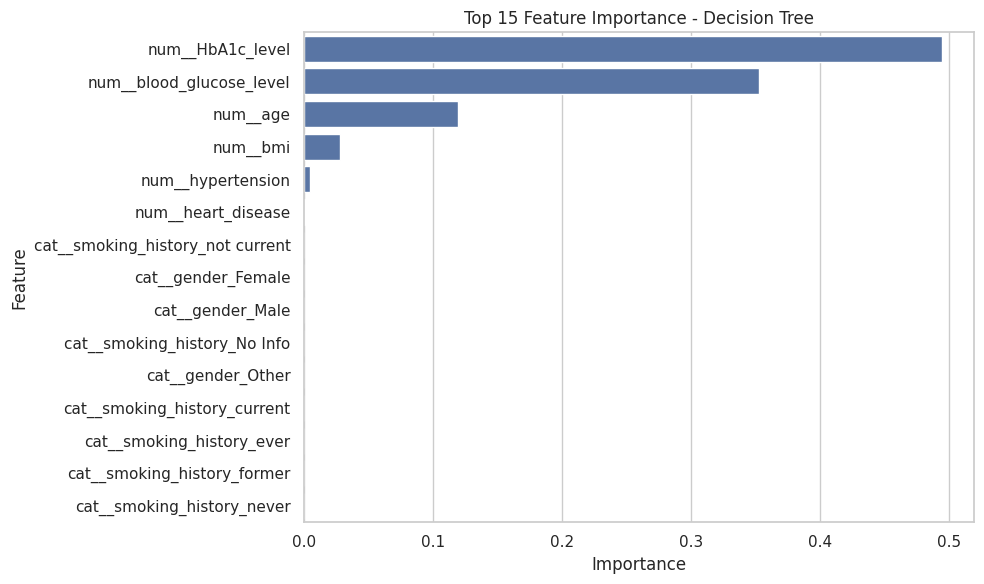

In [3]:
# ============================================================
# DECISION TREE CLASSIFICATION - DIABETES PREDICTION
# ============================================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# ============================================================
# 1. Create Decision Tree Model
# ============================================================

dt_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)

# ============================================================
# 2. Train Model
# ============================================================

dt_model.fit(X_train_processed, y_train)

print("Decision Tree Model Trained Successfully!")

# ============================================================
# 3. Predictions
# ============================================================

y_train_pred = dt_model.predict(X_train_processed)
y_test_pred = dt_model.predict(X_test_processed)

# ============================================================
# 4. Accuracy
# ============================================================

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("\nTraining Accuracy:", round(train_accuracy, 4))
print("Testing Accuracy :", round(test_accuracy, 4))

# ============================================================
# 5. Classification Report
# ============================================================

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_test,
    y_test_pred,
    target_names=["No Diabetes", "Diabetes"]
))

# ============================================================
# 6. Feature Importance
# ============================================================

importance = pd.DataFrame({
    "Feature": X_train_processed.columns,
    "Importance": dt_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nFeature Importance:")
display(importance.head(15))

# ============================================================
# 7. Visualize Feature Importance
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importance - Decision Tree")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

DECISION TREE EVALUATION
Accuracy  : 0.8707
Precision : 0.3997
Recall    : 0.9292
F1-Score  : 0.5590
ROC-AUC   : 0.9713

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.99      0.87      0.92     17534
    Diabetes       0.40      0.93      0.56      1696

    accuracy                           0.87     19230
   macro avg       0.70      0.90      0.74     19230
weighted avg       0.94      0.87      0.89     19230



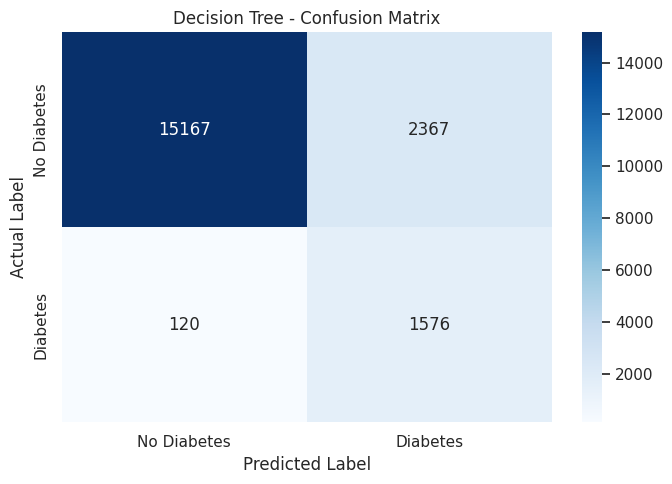

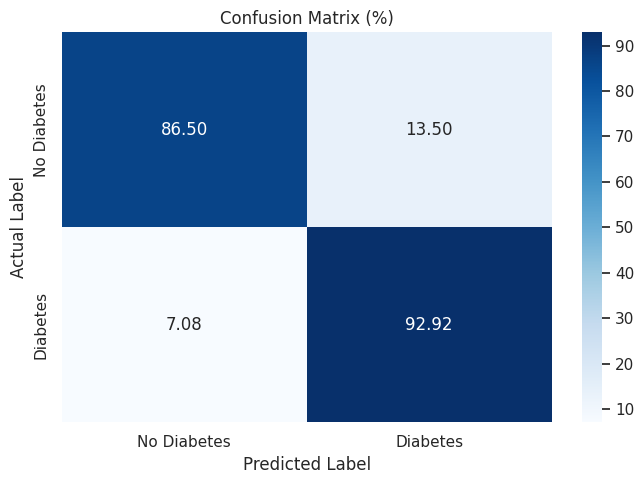

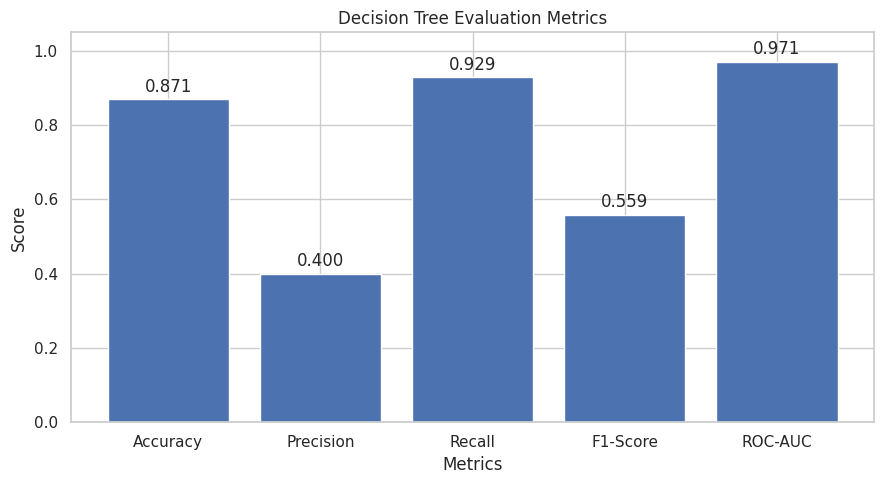

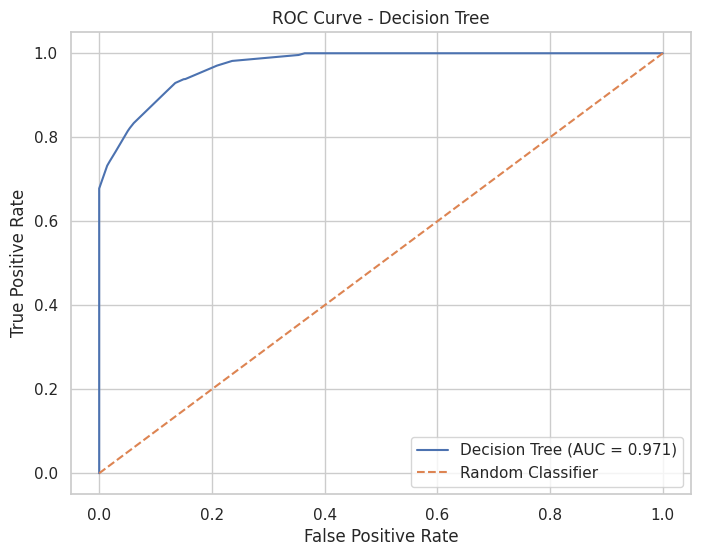

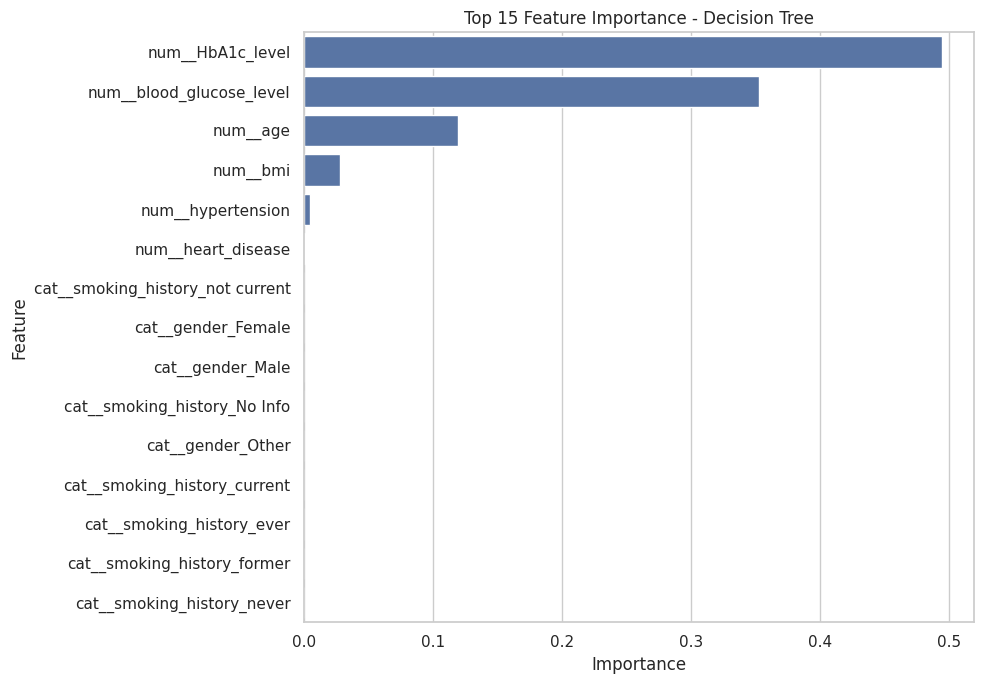


Final Evaluation Results:


,Metric,Score
0,Accuracy,0.870671
1,Precision,0.399696
2,Recall,0.929245
3,F1-Score,0.558964
4,ROC-AUC,0.971252


In [4]:
# ============================================================
# DECISION TREE - VISUALIZATION & EVALUATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

# ============================================================
# 1. Predictions
# ============================================================

y_pred = dt_model.predict(X_test_processed)

# Probability for ROC-AUC
y_prob = dt_model.predict_proba(X_test_processed)[:, 1]

# ============================================================
# 2. Evaluation Metrics
# ============================================================

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print("=" * 60)
print("DECISION TREE EVALUATION")
print("=" * 60)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

# ============================================================
# 3. Classification Report
# ============================================================

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Diabetes", "Diabetes"],
        zero_division=0
    )
)

# ============================================================
# 4. Confusion Matrix
# ============================================================

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

# ============================================================
# 5. Confusion Matrix as Percentage
# ============================================================

cm_percent = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis] * 100

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_percent,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.title("Confusion Matrix (%)")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

# ============================================================
# 6. Evaluation Metrics Visualization
# ============================================================

metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1,
    "ROC-AUC": roc_auc
}

plt.figure(figsize=(9, 5))

bars = plt.bar(metrics.keys(), metrics.values())

plt.ylim(0, 1.05)
plt.title("Decision Tree Evaluation Metrics")
plt.ylabel("Score")
plt.xlabel("Metrics")

for bar, value in zip(bars, metrics.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

# ============================================================
# 7. ROC Curve
# ============================================================

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Decision Tree (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve - Decision Tree")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()

# ============================================================
# 8. Feature Importance
# ============================================================

importance = pd.DataFrame({
    "Feature": X_train_processed.columns,
    "Importance": dt_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importance - Decision Tree")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# ============================================================
# 9. Final Result Table
# ============================================================

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

print("\nFinal Evaluation Results:")
display(results)